In [1]:
import pandas as pd
import numpy as np

### Datan esikäsittely

In [2]:
logs = pd.read_csv("ALL_logs_kurssidata.csv", sep=";")
print(logs.columns)
print(logs.head(6))
print(logs.dtypes)

Index(['Aika', 'Tapahtuman konteksti', 'Komponentti', 'Tapahtuman nimi',
       'Kuvaus', 'Alkuperä'],
      dtype='object')
                   Aika                  Tapahtuman konteksti  Komponentti  \
0   3.02.2026, 11.48.49      Kurssi: Esi- ja alkuopetus kl-25   Lokitiedot   
1   3.02.2026, 11.47.44      Kurssi: Esi- ja alkuopetus kl-25  Järjestelmä   
2   3.02.2026, 00.48.00         Tentti: Tentti 2.5.-16.5.2025       Tentti   
3   3.02.2026, 00.47.46  Tentti: Uusintatentti 6.6.-13.6.2025       Tentti   
4   3.02.2026, 00.39.38      Kurssi: Esi- ja alkuopetus kl-25  Järjestelmä   
5  30.01.2026, 18.27.07      Kurssi: Esi- ja alkuopetus kl-25   Lokitiedot   

         Tapahtuman nimi                                             Kuvaus  \
0  Lokiraportti katsottu  The user with id '179434' viewed the log repor...   
1           Kurssi nähty  The user with id '179434' viewed the course wi...   
2  Kurssin moduuli nähty  The user with id '268877' viewed the 'quiz' ac...   
3  Kurssin m

Poistettavat idt:

179434, 
179631,
44240,
14552,
14294,
4688,
54402,
39644,
87979,
15115,
31281,
173796,
44240,
2067,
204691,
48118,
Id '-1’ 

In [3]:
l = ["179434", "179631", "44240", "14552", "14294", "4688", "54402", "39644", "87979", "15115", "31281", "173796",
      "44240", "2067", "204691", "48118", "-1" ]
logs1 = logs.copy()

print(logs1.shape)
print(logs1.shape)
for i in l:
    colname = "Incl "+i
    logs1[colname] = logs1["Kuvaus"].str.contains(i)
    logs1 = logs1[logs1[colname] == False]

    print(logs1[colname].unique())
    print(logs1.shape)

    logs1 = logs1.drop([colname], axis=1)

    print(logs1.shape)
    print("----")
del colname

(86381, 6)
(86381, 6)
[False]
(84842, 7)
(84842, 6)
----
[False]
(84838, 7)
(84838, 6)
----
[False]
(83456, 7)
(83456, 6)
----
[False]
(82527, 7)
(82527, 6)
----
[False]
(82251, 7)
(82251, 6)
----
[False]
(82179, 7)
(82179, 6)
----
[False]
(82167, 7)
(82167, 6)
----
[False]
(82116, 7)
(82116, 6)
----
[False]
(82113, 7)
(82113, 6)
----
[False]
(81139, 7)
(81139, 6)
----
[False]
(81075, 7)
(81075, 6)
----
[False]
(80603, 7)
(80603, 6)
----
[False]
(80603, 7)
(80603, 6)
----
[False]
(79917, 7)
(79917, 6)
----
[False]
(78939, 7)
(78939, 6)
----
[False]
(78602, 7)
(78602, 6)
----
[False]
(76423, 7)
(76423, 6)
----


Haetaan uniikit idt

In [4]:
import re
logs1 = logs1[logs1["Kuvaus"].str.contains(r"^The user with id '") == True]

print(logs1.shape)

descs = logs1["Kuvaus"]
descs = descs.str.replace("The user with id '", "")
descs = descs.str.split("'", n=1)

#print(descs.shape)
#print(descs.head(5))

descs = descs.str.get(0)

#print(descs.head(5))

logs1["käyttäjä id"] = descs

print(len(logs1["käyttäjä id"].unique()))

del descs
logs1 = logs1.dropna(subset=["käyttäjä id"])

print(len(logs1["käyttäjä id"].unique()))
#print(logs1["käyttäjä id"].unique())
print(logs1.head(3))

ids = logs1["käyttäjä id"].unique()

(76002, 6)
249
249
                  Aika                  Tapahtuman konteksti  Komponentti  \
2  3.02.2026, 00.48.00         Tentti: Tentti 2.5.-16.5.2025       Tentti   
3  3.02.2026, 00.47.46  Tentti: Uusintatentti 6.6.-13.6.2025       Tentti   
4  3.02.2026, 00.39.38      Kurssi: Esi- ja alkuopetus kl-25  Järjestelmä   

         Tapahtuman nimi                                             Kuvaus  \
2  Kurssin moduuli nähty  The user with id '268877' viewed the 'quiz' ac...   
3  Kurssin moduuli nähty  The user with id '268877' viewed the 'quiz' ac...   
4           Kurssi nähty  The user with id '268877' viewed the course wi...   

  Alkuperä käyttäjä id  
2      web      268877  
3      web      268877  
4      web      268877  


In [5]:
active_ids = []
admin_names = [
    'Participation report viewed',
    'Arviointitaulukko on nähty',
    'Tentin raporttia katsottu',
    'Lokiraportti katsottu',
    'Tapahtuma luotu',
    'Paikka luotu',
    'Kurssin moduuli luotu',
    'Tentin poikkeuspääsy poistettu',
    'Osion sekoitus päivitetty',
    'Tentin arviointi päivitetty',
    'Kysymys luotu',
    'Aktiviteettiraportti nähty',
    'Arviointilomake on nähty',
    'Kysymyskategoria luotu',
    'Tentin muokkaussivua katsottu',
    'Arviointikohde luotu',
    'Kurssin moduuli päivitetty',
    'Arviointikohde päivitetty',
    'Kurssin varmuuskopio luotu',
    'Paikka poistettu',
    'Nähty arvioijan raportti',
    'Statistics report viewed',
    'Kurssin osio päivitettiin',
    'Kysymyskategoria katsottu',
    'Tentin poikkeuspääsy luotu',
    'Kysymys katsottu',
    'Kysymys päivitetty',
    'Kurssin osio luotiin',
    'Kysymys poistettu',
    'Kurssin moduuli poistettu',
    'Tentin suorituskerta arvioitu uudelleen',
    'Suorituskerta katsottu uudelleen',
    'Tentin esikatselu aloitettu',
    'Arviointikohde poistettu',
    'Kurssin osio poistettiin',
    'Arvosana poistettu',
    'Palautus on arvioitu.',
    'Käyttäjä poistettu kurssilta',
    'Kaikki palautukset ladatataan',
    'Kysymys siirretty',
    'Rooli määrätty',
    'Tapahtuma päivitetty',
    'Kurssikuvaus nähty']

for i in ids:
    df = logs1[logs1["käyttäjä id"] == i]
    events = df["Tapahtuman nimi"].unique()
    inc = False
    for j in admin_names:
        if j in events:
            inc = True
            break
    if not inc:
        active_ids.append(i)

print(len(active_ids))

active_names = ["Jotain sisältöä on lähetetty", "Tiedosto on lisätty", "Palautus on lähetetty", "Palautus on luotu", "Tenttivastaus palautettu", "Kommentti luotiin"]

for i in active_ids:
    df = logs1[logs1["käyttäjä id"] == i]
    events = df["Tapahtuman nimi"].unique()
    inc = False
    for j in active_names:
        if j in events:
            inc = True
            break
    if not inc:
        active_ids.remove(i)

print(len(active_ids))

del df
del inc
del events

ids = active_ids
logs1 = logs1[logs1["käyttäjä id"].isin(active_ids)]

print(len(logs1['käyttäjä id'].unique()))
print(len(ids))

246
242
242
242


Haetaan päivämäärät

In [6]:
from datetime import datetime, timedelta

logs1["Aika"] = pd.to_datetime(logs1["Aika"], format="%d.%m.%Y, %H.%M.%S")

print(logs1["Aika"].head(5))

start = logs1["Aika"].min()
end = logs1["Aika"].max()
quartile = 0.25
neljannes = ((end-start))*quartile

print(end)
print(start)
print((end-start).days)
print(logs1.shape)

2    2026-02-03 00:48:00
3    2026-02-03 00:47:46
4    2026-02-03 00:39:38
21   2026-01-28 10:52:46
22   2026-01-26 17:25:39
Name: Aika, dtype: datetime64[ns]
2026-02-03 00:48:00
2025-03-02 08:20:29
337
(75150, 7)


Etsitään tapoja ennustaa myöhempää aktiivisuutta aiemman perusteella.

### Palautusten määrä

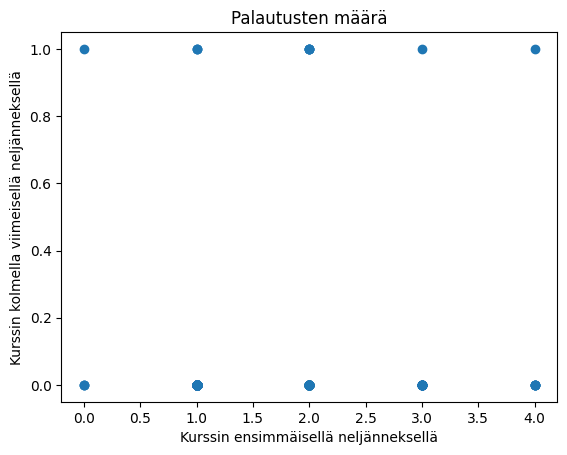

Range of y values:
1.0 0.0
Range of x values:
4.0 0.0


In [7]:
import matplotlib.pyplot as plt
activity = logs1[logs1["Tapahtuman nimi"].isin(["Tenttivastaus palautettu", "Palautus on lähetetty"])]

early = activity[activity["Aika"]-start <= neljannes]
later = activity[activity["Aika"]-start > neljannes]

earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)

for i in ids:
    earlyactivity = len(early[early["käyttäjä id"] == i].index)
    lateractivity = len(later[later["käyttäjä id"] == i].index)
    
    earlyavgs = np.append(earlyavgs, earlyactivity)
    lateravgs = np.append(lateravgs, lateractivity)

plt.title("Palautusten määrä")
plt.xlabel("Kurssin ensimmäisellä neljänneksellä")
plt.ylabel("Kurssin kolmella viimeisellä neljänneksellä")
plt.scatter(earlyavgs, lateravgs)
plt.show()

print("Range of y values:")
print(lateravgs.max(), lateravgs.min())
print("Range of x values:")
print(earlyavgs.max(), earlyavgs.min())

### Vähintään yhden tentin parissa kerrallaan käytetty aika

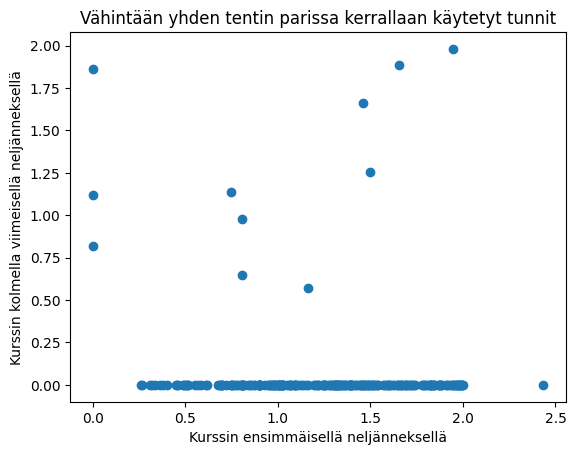

Range of y values:
1.98 0.0
Range of x values:
2.435277777777778 0.0


In [8]:
activity = logs1[logs1["Tapahtuman nimi"].isin(["Tenttivastaus palautettu", "Tenttiin vastaaminen aloitettu"])]

early = activity[activity["Aika"]-start <= neljannes]
later = activity[activity["Aika"]-start > neljannes]

earlyavgs = np.empty(shape=0)
lateravgs = np.empty(shape=0)

earlyactivity = early.sort_values(by=["käyttäjä id", "Aika"]).to_numpy()
lateractivity = later.sort_values(by=["käyttäjä id", "Aika"]).to_numpy()

def compute_total_hours_on_at_least_one_exam(table, colname):
    ac = np.empty(shape=0)
    ids = np.empty(shape=0)
    if len(table) == 0:
        return pd.DataFrame({"id": pd.Series(["emptyrow"]), colname: pd.Series([0])})
    
    initial = True
    cur_user = None

    for l in table:
        if l[6] != cur_user: #Check if user has changed
            ids = np.append(ids, l[6])
            cur_user = l[6]
            counter = 0 #tracks how many exams are being worked at a time
            
            if initial:
                initial = False
            else:
                ac = np.append(ac, total_time)
            
            total_time = 0 #total time spent by a user on one or more exams at a time
        
        if l[3] == "Tenttiin vastaaminen aloitettu":
            if counter == 0:
                start = l[0] #last recorded exam start
            counter += 1
        
        else: #in other words, if event_name == "Tenttivastaus palautettu"
            counter -= 1
        
            if counter == 0:
                total_time += (l[0]-start).total_seconds()/3600 #1h = 3600s
        
            elif counter < 0: #if event_name "Tenttivastaus palautettu" for any reason comes before a corresponding "Tenttiin vastaaminen aloitettu"
                counter = 0 #these cases are ignored
    ac = np.append(ac, total_time)
    return pd.DataFrame({"id": pd.Series(ids), colname: pd.Series(ac)})

earlyavgs = compute_total_hours_on_at_least_one_exam(earlyactivity, "early hours")
lateravgs = compute_total_hours_on_at_least_one_exam(lateractivity, "later hours")
df_plot = earlyavgs.merge(lateravgs, on="id", how="outer")
df_plot = df_plot.fillna(0)
df_plot = df_plot[df_plot["id"] != "emptyrow"]

plt.title("Vähintään yhden tentin parissa kerrallaan käytetyt tunnit")
plt.xlabel("Kurssin ensimmäisellä neljänneksellä")
plt.ylabel("Kurssin kolmella viimeisellä neljänneksellä")
plt.scatter(df_plot["early hours"], df_plot["later hours"])
plt.show()

print("Range of y values:")
print(df_plot["later hours"].max(), df_plot["later hours"].min())
print("Range of x values:")
print(df_plot["early hours"].max(), df_plot["early hours"].min())

### Käytetyt tunnit per tentti

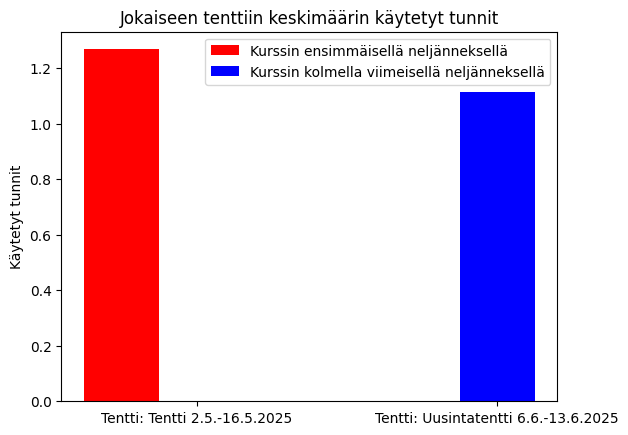

In [9]:
activity = logs1[logs1["Tapahtuman nimi"].isin(["Tenttivastaus palautettu", "Tenttiin vastaaminen aloitettu"])]

early = activity[activity["Aika"]-start <= neljannes]
later = activity[activity["Aika"]-start > neljannes]

def compute_total_hours_on_a_specific_exam(table, colname, colname2):
    ac = np.empty(shape=0)
    contxs = np.empty(shape=0)
    user_n = np.empty(shape=0)
    if len(table) == 0:
        return pd.DataFrame({"contx": pd.Series(["emptyrow"]), colname: pd.Series([0])})
    
    initial = True

    for l in table:
        if initial: #Initialize
            initial = False
            context_hours = 0
            user_hours = 0
            cur_context = l[1]
            cur_user = l[6]
            n_users = 0
            counter = 0
        
        if l[1] != cur_context: #Check if context has changed
            contxs = np.append(contxs, cur_context)
            context_hours += user_hours
            ac = np.append(ac, context_hours)
            n_users += 1
            user_n = np.append(user_n, n_users)
            n_users = 0
            context_hours = 0
            cur_context = l[1]
            cur_user = l[6]
            user_hours = 0
            counter = 0
        
        if l[6] != cur_user: #Check if user has changed
            context_hours += user_hours
            user_hours = 0
            counter = 0
            cur_user = l[6]
            n_users += 1

        if l[3] == "Tenttiin vastaaminen aloitettu":
            if counter == 0:
                start = l[0] #last recorded exam start
            counter += 1
        
        else: #in other words, if event_name == "Tenttivastaus palautettu"
            counter -= 1

            if counter == 0:
                user_hours += (l[0]-start).total_seconds()/3600 #1h = 3600s
            
            elif counter < 0: #if event_name "Tenttivastaus palautettu" for any reason comes before a corresponding "Tenttiin vastaaminen aloitettu"
                counter = 0 #these cases are ignored
    contxs = np.append(contxs, cur_context)
    ac = np.append(ac, context_hours)
    n_users += 1
    user_n = np.append(user_n, n_users)
    return pd.DataFrame({"contx": pd.Series(contxs), colname: pd.Series(ac), colname2: pd.Series(user_n)})

earlyactivity = early.sort_values(by=["Tapahtuman konteksti", "käyttäjä id", "Aika"]).to_numpy()
lateractivity = later.sort_values(by=["Tapahtuman konteksti", "käyttäjä id", "Aika"]).to_numpy()
earlyavgs = compute_total_hours_on_a_specific_exam(earlyactivity, "hours_early", "n_users_early")
lateravgs = compute_total_hours_on_a_specific_exam(lateractivity, "hours_later", "n_users_later")

df_plot = earlyavgs.merge(lateravgs, on="contx", how="outer")
df_plot = df_plot.fillna(0)
df_plot = df_plot[df_plot["contx"] != "emptyrow"]

y1 = [df_plot["hours_early"].to_numpy()[i]/df_plot["n_users_early"].to_numpy()[i] if df_plot["n_users_early"].to_numpy()[i] > 0 else 0 for i in range(len(df_plot["hours_early"].to_numpy()))]
y2 = [df_plot["hours_later"].to_numpy()[i]/df_plot["n_users_later"].to_numpy()[i] if df_plot["n_users_later"].to_numpy()[i] > 0 else 0 for i in range(len(df_plot["hours_later"].to_numpy()))]

plt.title("Jokaiseen tenttiin keskimäärin käytetyt tunnit")
plt.ylabel("Käytetyt tunnit")
x1 = np.arange(len(df_plot["hours_early"].to_list()))
x2 = [x + 0.25 for x in x1]
plt.bar(x1, y1, color='r', width=0.25, label="Kurssin ensimmäisellä neljänneksellä")
plt.bar(x2, y2, color='b', width=0.25, label="Kurssin kolmella viimeisellä neljänneksellä")
plt.xticks([r + 0.25 for r in range(len(df_plot["hours_early"].to_list()))], df_plot["contx"].to_list())
plt.legend()
plt.show()

### Palauttajien määrä per aikaväli

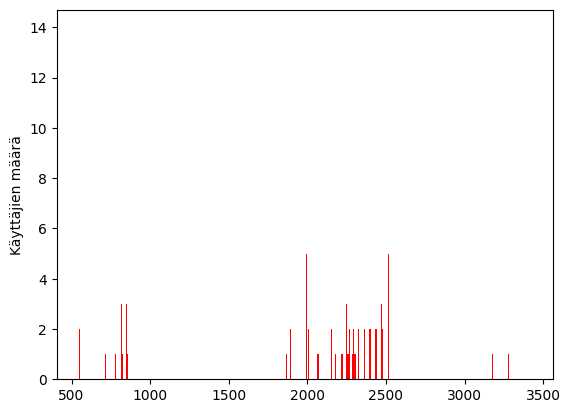

In [10]:
from math import floor
activity = logs1[logs1["Tapahtuman nimi"].isin(["Tenttivastaus palautettu", "Palautus on lähetetty"])].sort_values(by=["Aika"]).to_numpy()

intervalm = timedelta(minutes=45)

numbers = np.empty(shape=0)
counted_ids = []
last_n = 0

for l in activity:
    new_n = (l[0]-start)/intervalm

    if new_n-last_n >= 2: #if there is a timeskip
        numbers = np.append(numbers, len(counted_ids))
        counted_ids = []
        n = floor(new_n-last_n)

        for i in range(0, n-1):
            numbers = np.append(numbers, 0)
    
    if new_n-last_n >= 1:
        numbers = np.append(numbers, len(counted_ids))
        counted_ids = []
        last_n = floor(new_n)
    
    if l[6] not in counted_ids:
        counted_ids.append(l[6])

numbers = np.append(numbers, len(counted_ids))
nonzeros = np.nonzero(numbers)[0]

firstnonzero = nonzeros[0]
lastnonzero = nonzeros[len(nonzeros)-1]
x1 = np.arange(len(numbers))
plt.bar(x1[firstnonzero:lastnonzero], numbers[firstnonzero:lastnonzero], color='r', width=1)
plt.ylabel("Käyttäjien määrä")
plt.show()